In [1]:
import pandas as pd 
import numpy as np 
import polars as pl
from typing import List
from collections import Counter
import glob, os

import matplotlib.pyplot as plt
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats("retina")
from matplotlib.ticker import FuncFormatter
import matplotlib as mpl
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans", "sans-serif"],
    "font.size": 12,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
})


import yaml
with open("../../src/configs.yml", "r") as configs:
    configs = yaml.safe_load(configs)

DATAPATH = configs["SERVER_DATA"]
ROOTPATH = configs["SERVER_WD"]

In [2]:
sets_df = pd.read_csv("../../data-public/subreddit_sets.csv")

subreddit_sets = {
    name: set(group["subreddit"])
    for name, group in sets_df.groupby("set")
}

matched1_indp = subreddit_sets["matched1_indp"]
matched2_indp= subreddit_sets["matched2_indp"]
matched2_conn = subreddit_sets["matched2_conn"]
random = subreddit_sets["random"]
banned = subreddit_sets["banned"]

In [3]:
from src.utils.data_loader_polars import load_filtered_data

years = range(2006, 2020)
cols = ["id","author","subreddit","created_utc"]
X0 = 10; N0 = 1
X1 = 20; N1 = 10
X2 = "inf"; N2 = 1
covs1 = "lifetime_d"
covs2 = "lifetime_d_n_post_author_till2019_log"

def load_post_subreddit(subm_input_fpath, comm_input_fpath, subrs, years=years, cols=cols):
    subm_df = load_filtered_data(years=years, data_dir=subm_input_fpath, filetype="submissions",filter_bots=False).select(cols)
    comm_df = load_filtered_data(years=years, data_dir=comm_input_fpath, filetype="comments",filter_bots=False).select(cols)
    subm_df = subm_df.with_columns(pl.lit("submission").alias("kind"))
    comm_df = comm_df.with_columns(pl.lit("comment").alias("kind"))
    post_df = pl.concat([subm_df, comm_df], how="vertical").filter(pl.col("subreddit").is_in(subrs))
    return post_df

subm_input_banned = f"{DATAPATH}/filtered-data/submissions/subm-from-subr-banned-2020/" 
comm_input_banned = f"{DATAPATH}/filtered-data/comments/comm-from-subr-banned-2020/" 
subm_input_matched1_indp = f"{DATAPATH}/filtered-data/submissions/subm-from-subr-banned-2020-subset3274-match-{covs1}-X{X0}N{N0}/" 
comm_input_matched1_indp = f"{DATAPATH}/filtered-data/comments/comm-from-subr-banned-2020-subset3274-match-{covs1}-X{X0}N{N0}/" 
subm_input_matched2_indp = f"{DATAPATH}/filtered-data/submissions/subm-from-subr-banned-2020-subset3274-match-{covs2}-X{X1}N{N1}/" 
comm_input_matched2_indp = f"{DATAPATH}/filtered-data/comments/comm-from-subr-banned-2020-subset3274-match-{covs2}-X{X1}N{N1}/" 
subm_input_matched2_conn = f"{DATAPATH}/filtered-data/submissions/subm-from-subr-banned-2020-subset3274-match-{covs2}-X{X2}N{N2}/" 
comm_input_matched2_conn = f"{DATAPATH}/filtered-data/comments/comm-from-subr-banned-2020-subset3274-match-{covs2}-X{X2}N{N2}/" 
subm_input_random = f"{DATAPATH}/filtered-data/submissions/subm-from-subr-banned-2020-subset3274-random/" 
comm_input_random = f"{DATAPATH}/filtered-data/comments/comm-from-subr-banned-2020-subset3274-random/" 

post_banned = load_post_subreddit(subm_input_banned, comm_input_banned, banned)
post_matched1_indp = load_post_subreddit(subm_input_matched1_indp, comm_input_matched1_indp, matched1_indp)
post_matched2_indp = load_post_subreddit(subm_input_matched2_indp, comm_input_matched2_indp, matched2_indp)
post_matched2_conn = load_post_subreddit(subm_input_matched2_conn, comm_input_matched2_conn, matched2_conn)
post_random = load_post_subreddit(subm_input_random, comm_input_random, random)


******************
Loading Submissions from /cinddata/reddit-ban-study/filtered-data/submissions/subm-from-subr-banned-2020/...
	loading: 2006
	loading: 2007
	loading: 2008
	loading: 2009
	loading: 2010
	loading: 2011
	loading: 2012
	loading: 2013
	loading: 2014
	loading: 2015
	loading: 2016


	loading: 2017
	loading: 2018
	loading: 2019
******************
Loading Comments from /cinddata/reddit-ban-study/filtered-data/comments/comm-from-subr-banned-2020/...
	loading: 2006
	loading: 2007
	loading: 2008
	loading: 2009
	loading: 2010
	loading: 2011
	loading: 2012
	loading: 2013
	loading: 2014
	loading: 2015
	loading: 2016
	loading: 2017
	loading: 2018
	loading: 2019
******************
Loading Submissions from /cinddata/reddit-ban-study/filtered-data/submissions/subm-from-subr-banned-2020-subset3274-match-lifetime_d-X10N1/...
	loading: 2006
	loading: 2007
	loading: 2008
	loading: 2009
	loading: 2010
	loading: 2011
	loading: 2012
	loading: 2013
	loading: 2014
	loading: 2015
	loading: 2016
	loading: 2017
	loading: 2018
	loading: 2019
******************
Loading Comments from /cinddata/reddit-ban-study/filtered-data/comments/comm-from-subr-banned-2020-subset3274-match-lifetime_d-X10N1/...
	loading: 2006
	loading: 2007
	loading: 2008
	loading: 2009
	loading: 2010
	loading: 2011
	load

In [4]:
groups = {
    "banned":{
        "subr_list": banned,                  
        "post_df": post_banned, 
        "label": "BANNED"},
    "matched1_indp":{
        "subr_list": matched1_indp,    
        "post_df": post_matched1_indp, 
        "label": "MATCHED1-INDP"},
    "matched2_indp":{
        "subr_list": matched2_indp,    
        "post_df": post_matched2_indp, 
        "label": "MATCHED2-INDP"},
    "matched2_conn":{
        "subr_list": matched2_conn,    
        "post_df": post_matched2_conn, 
        "label": "MATCHED2-CONN"},
    "random":{
        "subr_list": random,    
        "post_df": post_random, 
        "label": "RANDOM"},
}

In [5]:
import polars as pl
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter


def ensure_datetime(df, col="created_utc"):
    dtype = df.schema[col]

    if dtype in [pl.Int32, pl.Int64, pl.UInt32, pl.UInt64, pl.Float32, pl.Float64]:
        return df.with_columns(
            pl.from_epoch(pl.col(col), time_unit="s").alias("dt")
        )
    else:
        return df.with_columns(
            pl.col(col).cast(pl.Datetime, strict=False).alias("dt")
        )


def build_truncated_ts(groups, kind_col="kind", length="1mo", length_label="month"):
    out = []

    for _, g in groups.items():
        df = ensure_datetime(g["post_df"])

        df = df.with_columns([
            pl.lit(g["label"]).alias("group"),
            pl.col("dt").dt.truncate(length).alias(length_label),
        ])

        monthly = (
            df.group_by(["group", length_label])
            .agg([
                pl.col("author").n_unique().alias("active_users"),
                (pl.col(kind_col) == "submission").sum().alias("submissions"),
                (pl.col(kind_col) == "comment").sum().alias("comments"),
            ])
        )

        out.append(monthly)

    return pl.concat(out, how="vertical").sort(["group", length_label])

In [6]:
monthly_ts = build_truncated_ts(groups)
monthly_ts.head()

group,month,active_users,submissions,comments
str,datetime[μs],u32,u32,u32
"""BANNED""",2006-02-01 00:00:00,11,45,14
"""BANNED""",2006-03-01 00:00:00,28,92,41
"""BANNED""",2006-04-01 00:00:00,11,31,10
"""BANNED""",2006-05-01 00:00:00,16,37,9
"""BANNED""",2006-06-01 00:00:00,10,16,9


In [7]:
yearly_ts = build_truncated_ts(groups, length="1y", length_label="year")

In [8]:
# yearly_ts.filter((pl.col("group")=="BANNED") & (pl.col("year")>=pl.datetime(2010, 1, 1)))
x_banned_2015 = yearly_ts.filter((pl.col("group")=="BANNED") & (pl.col("year")==pl.datetime(2015, 1, 1)))
x_banned_2016 = yearly_ts.filter((pl.col("group")=="BANNED") & (pl.col("year")==pl.datetime(2016, 1, 1)))
growth_user = (x_banned_2016["active_users"].item() - x_banned_2015["active_users"].item()) / x_banned_2015["active_users"].item() * 100
growth_submissions = (x_banned_2016["submissions"].item() - x_banned_2015["submissions"].item()) / x_banned_2015["submissions"].item() * 100
growth_comments = (x_banned_2016["comments"].item() - x_banned_2015["comments"].item()) / x_banned_2015["comments"].item() * 100

print(f"Growth in active users from 2015 to 2016: {growth_user:.1f} %")
print(f"Growth in submissions from 2015 to 2016: {growth_submissions:.1f} %")
print(f"Growth in comments from 2015 to 2016: {growth_comments:.1f} %")

Growth in active users from 2015 to 2016: 658.8 %
Growth in submissions from 2015 to 2016: 1334.4 %
Growth in comments from 2015 to 2016: 4187.7 %


In [9]:
from matplotlib.ticker import FuncFormatter
import matplotlib.dates as mdates


styles = {
    "banned": dict(color="darkred", linestyle="-", label=r"$B$"),
    "matched1_indp": dict(color="steelblue", linestyle="--", label=r"$M_{\mathrm{indp},1}$"),
    "matched2_indp": dict(color="darkgreen", linestyle="--", label=r"$M_{\mathrm{indp},2}$"),
    "matched2_conn": dict(color="darkorange", linestyle="-.", label=r"$M_{\mathrm{conn},2}$"),
    "random": dict(color="grey", linestyle=":", label=r"$U$"),
}

def plot_monthly_ts_log(
    monthly_ts,
    groups,
    metrics=("active_users", "submissions", "comments"),
    start="2006-01-01",
    end="2019-12-31",
):
    df = monthly_ts.to_pandas()
    df["month"] = pd.to_datetime(df["month"])

    df = df[(df["month"] >= start) & (df["month"] <= end)].copy()

    fig, axes = plt.subplots(
        nrows=1,
        ncols=len(metrics),
        figsize=(12, 3.2),
        sharex=True,
        # sharey=True,
        constrained_layout=True,
    )

    if len(metrics) == 1:
        axes = [axes]

    for ax, metric in zip(axes, metrics):

        for group_key, g in groups.items():
            label = g["label"]

            this = df[df["group"] == label].sort_values("month").copy()

            if this.empty:
                continue

            # important fix: use np.nan, not pd.NA
            y = this[metric].astype(float).replace(0, np.nan)

            ax.plot(
                this["month"],
                y,
                # label=label,
                linewidth=2.2 if group_key == "banned" else 1.7,
                alpha=1 if group_key == "banned" else 0.9,
                **styles.get(group_key, {}),
            )

        ax.set_yscale("log")
        ax.set_title(metric.replace("_", " "), fontsize=16)
        # ax.grid(axis="y", alpha=0.25)
        # ax.set_xlabel("month")
        ax.axvline(pd.to_datetime("2016-01-01"), linestyle="--", color="grey", alpha=0.3, linewidth=3)
        ax.set_ylim(1, 5e6)

        ax.xaxis.set_major_locator(mdates.YearLocator(base=4))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    axes[0].set_ylabel("monthly count, log scale", fontsize=14)

    # if running r/the_donald shaded version, comment this out to avoid double legend
    # handles, labels = axes[0].get_legend_handles_labels()
    # fig.legend(
    #     handles,
    #     labels,
    #     frameon=False,
    #     fontsize=10,
    #     loc="center left",
    #     bbox_to_anchor=(1.01, 0.5),
    # )

    return fig, axes

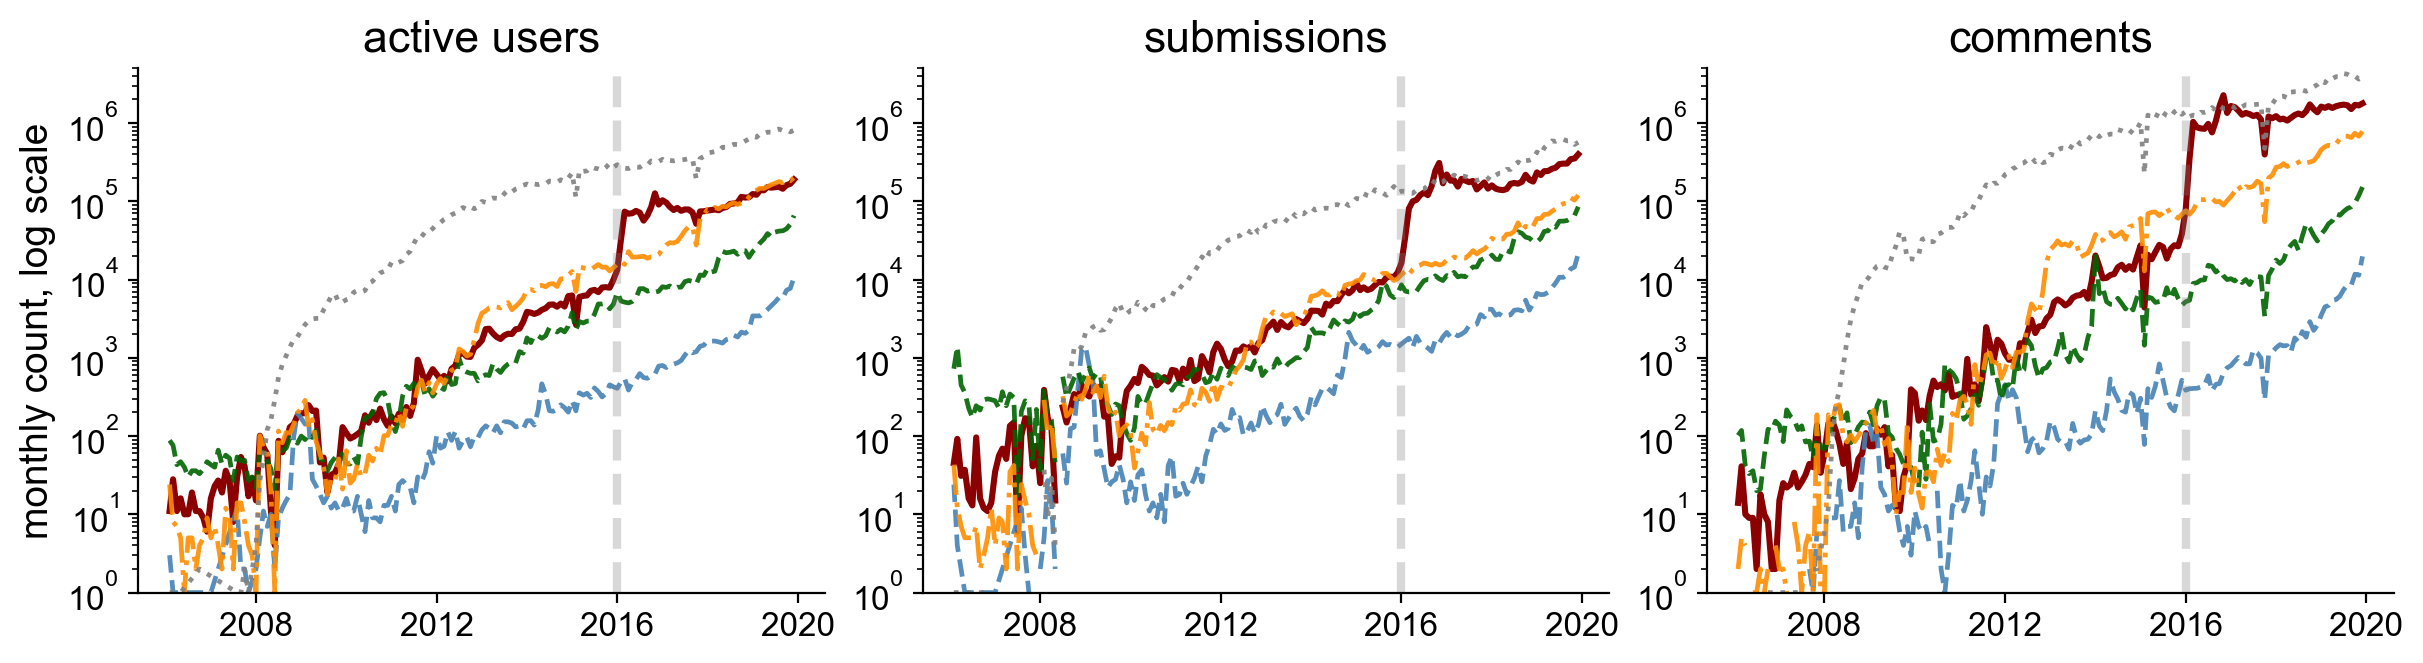

In [10]:
fig, axes = plot_monthly_ts_log(monthly_ts, groups)
# plt.savefig("../../output/mainbody/monthly_active_users_submissions_comments_2006_2019_5groups.png", dpi=300, bbox_inches="tight")
# plt.savefig("../../output/mainbody/monthly_active_users_submissions_comments_2006_2019_5groups.pdf", dpi=300, bbox_inches="tight")

In [11]:
donald = "the_donald"

banned_wo_donald = banned - {donald}
post_banned_wo_donald = post_banned.filter(pl.col("subreddit") != donald)

groups_shading = groups.copy()
groups_shading["banned_wo_donald"] = {
    "subr_list": banned_wo_donald,
    "post_df": post_banned_wo_donald,
    "label": "BANNED-WO-DONALD",
}

groups_shading["the_donald"] = {
    "subr_list": {donald},
    "post_df": post_banned.filter(pl.col("subreddit") == donald),
    "label": "THE-DONALD",
}

monthly_ts_shading = build_truncated_ts(groups_shading)
yearly_ts_shading = build_truncated_ts(groups_shading, length="1y", length_label="year")

In [12]:
yearly_ts_shading.filter(pl.col("group")=="THE-DONALD")

group,year,active_users,submissions,comments
str,datetime[μs],u32,u32,u32
"""THE-DONALD""",2015-01-01 00:00:00,1981,3272,16741
"""THE-DONALD""",2016-01-01 00:00:00,332778,1422320,11635536
"""THE-DONALD""",2017-01-01 00:00:00,273000,1571809,13313246
"""THE-DONALD""",2018-01-01 00:00:00,209778,972787,10926720
"""THE-DONALD""",2019-01-01 00:00:00,173015,873018,10015586


In [13]:
import matplotlib.patches as mpatches
import pandas as pd

def add_donald_shading(
    axes,
    monthly_ts_shading,
    metrics=("active_users", "submissions", "comments"),
    banned_label="BANNED",
    banned_wo_label="BANNED-WO-DONALD",
    color="darkred",
    alpha=0.12,
):
    df = monthly_ts_shading.to_pandas()
    df["month"] = pd.to_datetime(df["month"])

    for i, (ax, metric) in enumerate(zip(axes, metrics)):
        b = (
            df[df["group"] == banned_label][["month", metric]]
            .sort_values("month")
            .rename(columns={metric: "b"})
        )

        b_wo = (
            df[df["group"] == banned_wo_label][["month", metric]]
            .sort_values("month")
            .rename(columns={metric: "b_wo"})
        )

        merged = b.merge(b_wo, on="month", how="inner")

        # on log scale, avoid zero values in fill_between
        merged = merged[(merged["b"] > 0) & (merged["b_wo"] > 0)].copy()

        ax.fill_between(
            merged["month"],
            merged["b_wo"],
            merged["b"],
            color=color,
            alpha=alpha,
            zorder=0.5,
        )

    # add shaded patch to legend on first panel
    handles, labels = axes[0].get_legend_handles_labels()
    donald_patch = mpatches.Patch(
        facecolor="darkred",
        edgecolor="darkred",
        alpha=0.12,
        label=r"r/The_Donald"
    )

    handles.append(donald_patch)
    labels.append(r"r/The_Donald")

    fig.legend(
        handles,
        labels,
        frameon=False,
        fontsize=11,
        loc="center left",
        bbox_to_anchor=(1.0, 0.5),
    )

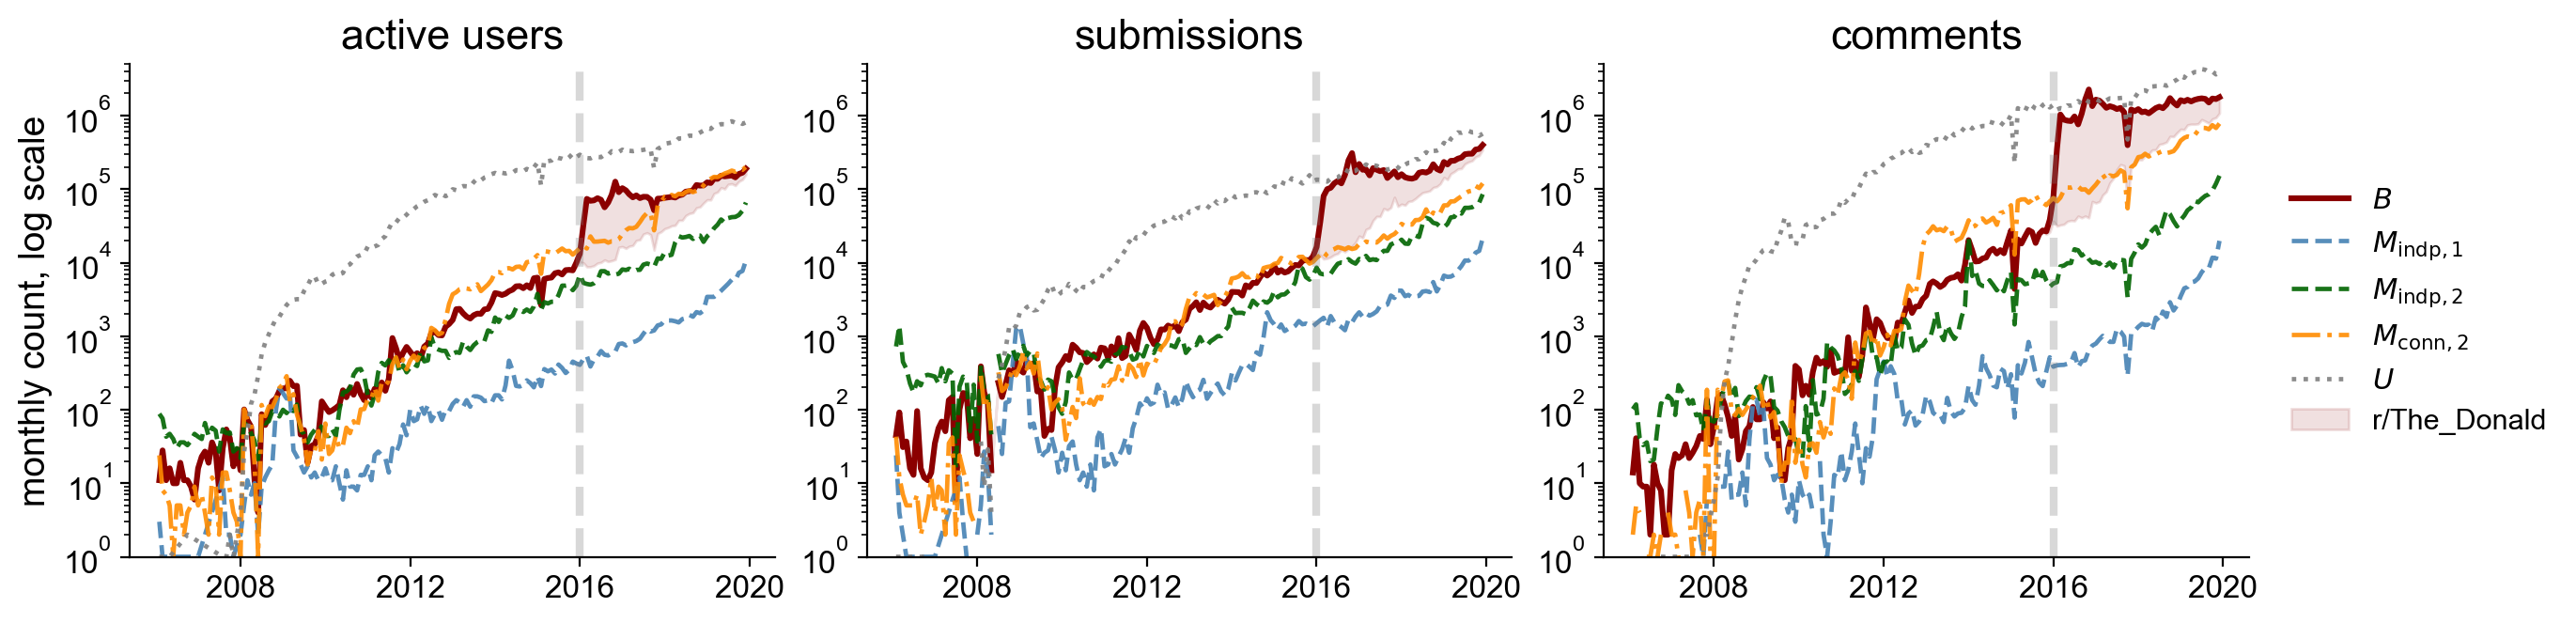

In [14]:
fig, axes = plot_monthly_ts_log(
    monthly_ts,
    groups,
    start="2006-01-01",
    end="2019-12-31",
)

add_donald_shading(
    axes,
    monthly_ts_shading,
    metrics=("active_users", "submissions", "comments"),
)

# plt.savefig("../../output/mainbody/monthly_active_users_submissions_comments_2006_2019_5groups.png", dpi=300, bbox_inches="tight")
# plt.savefig("../../output/mainbody/monthly_active_users_submissions_comments_2006_2019_5groups.pdf", dpi=300, bbox_inches="tight")

## leave-one-out analysis (sanity check)

In [16]:
groups_wo_donald = {
    "banned_wo_donald": {
        "subr_list": banned_wo_donald,
        "post_df": post_banned_wo_donald,
        "label": "BANNED-WO-DONALD"
    },
    "matched1_indp": {
        "subr_list": matched1_indp,
        "post_df": post_matched1_indp,
        "label": "MATCHED1-INDP"
    },
    "matched2_indp": {
        "subr_list": matched2_indp,
        "post_df": post_matched2_indp,
        "label": "MATCHED2-INDP"
    },
    "matched2_conn": {
        "subr_list": matched2_conn,
        "post_df": post_matched2_conn,
        "label": "MATCHED2-CONN"
    },
    "random": {
        "subr_list": random,
        "post_df": post_random,
        "label": "RANDOM"
    },
}

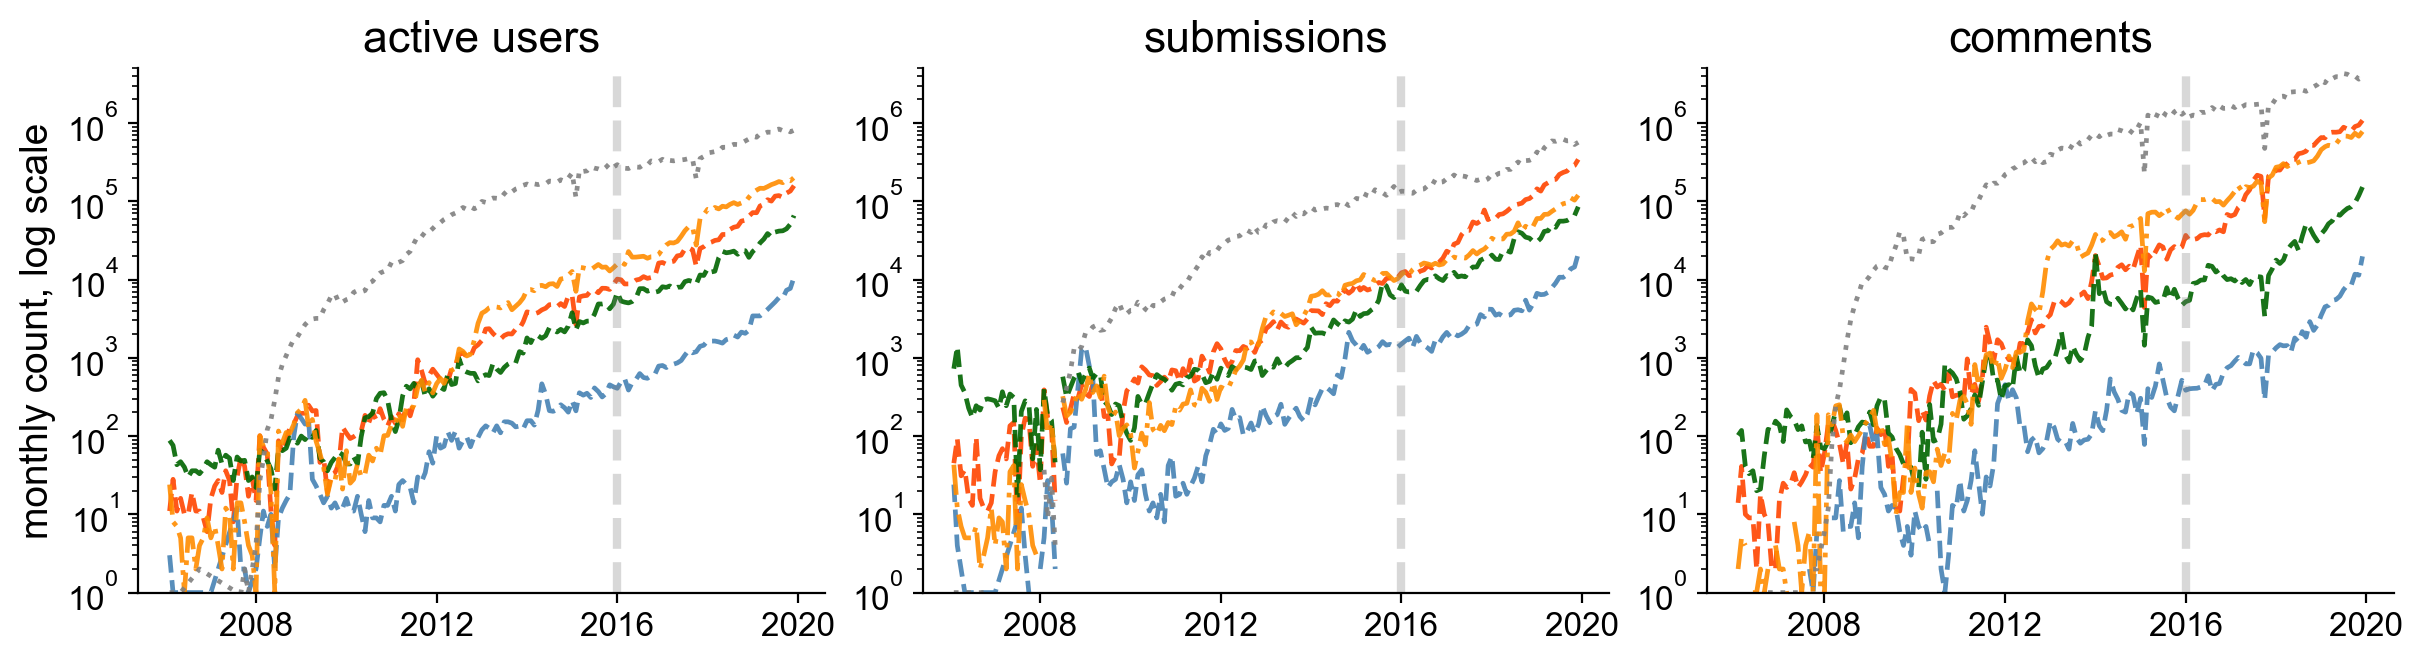

In [17]:
monthly_ts_wo_donald = build_truncated_ts(groups_wo_donald)

styles.update({
    "banned": dict(
        color="darkred",
        linestyle="-",
        label=r"$B$"
    ),
    "banned_wo_donald": dict(
        color="orangered",
        linestyle="--",
        label=r"$B$ excl. r/The_Donald"
    ),
    "the_donald": dict(
        color="darkorange",
        linestyle="-.",
        label=r"r/The_Donald"
    ),
})

fig, axes = plot_monthly_ts_log(
    monthly_ts_wo_donald,
    groups_wo_donald
)